In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [32]:
# !pip install torchmetrics

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
train_df = pd.read_csv("/content/drive/MyDrive/Cyber_Security_Threats/labelled_train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Cyber_Security_Threats/labelled_test.csv")
val_df = pd.read_csv("/content/drive/MyDrive/Cyber_Security_Threats/labelled_validation.csv")
train_df.head(10)

,processId,threadId,parentProcessId,userId,mountNamespace,argsNum,returnValue,sus_label
0,381,7337,1,100,4026532231,5,0,1
1,381,7337,1,100,4026532231,1,0,1
2,381,7337,1,100,4026532231,0,0,1
3,7347,7347,7341,0,4026531840,2,-2,1
4,7347,7347,7341,0,4026531840,4,0,1
5,7347,7347,7341,0,4026531840,4,3,1
6,7347,7347,7341,0,4026531840,2,0,1
7,7347,7347,7341,0,4026531840,1,0,1
8,7347,7347,7341,0,4026531840,4,0,1
9,7347,7347,7341,0,4026531840,4,3,1


In [35]:
train_df.shape, test_df.shape, val_df.shape

((763144, 8), (188967, 8), (188967, 8))

In [36]:
sum = 0
for data in [train_df.shape, test_df.shape, val_df.shape]:
  sum += data[0]

print(sum)

1141078


In [37]:
df = pd.concat([train_df, test_df, val_df], axis=0)
df.shape

(1141078, 8)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1141078 entries, 0 to 188966
Data columns (total 8 columns):
 #   Column           Non-Null Count    Dtype
---  ------           --------------    -----
 0   processId        1141078 non-null  int64
 1   threadId         1141078 non-null  int64
 2   parentProcessId  1141078 non-null  int64
 3   userId           1141078 non-null  int64
 4   mountNamespace   1141078 non-null  int64
 5   argsNum          1141078 non-null  int64
 6   returnValue      1141078 non-null  int64
 7   sus_label        1141078 non-null  int64
dtypes: int64(8)
memory usage: 78.4 MB


In [39]:
df.describe()

,processId,threadId,parentProcessId,userId,mountNamespace,argsNum,returnValue,sus_label
count,1.141078e+06,1.141078e+06,1.141078e+06,1.141078e+06,1.141078e+06,1.141078e+06,1.141078e+06,1.141078e+06
mean,6.909070e+03,6.913038e+03,2.467229e+03,1.437311e+02,4.026532e+09,2.671557e+00,3.018248e+00,1.520615e-01
std,1.816699e+03,1.807393e+03,2.862640e+03,3.500947e+02,1.726697e+02,1.250393e+00,3.223468e+02,3.590806e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,4.026532e+09,0.000000e+00,-1.150000e+02,0.000000e+00
25%,7.301000e+03,7.301000e+03,1.870000e+02,0.000000e+00,4.026532e+09,1.000000e+00,0.000000e+00,0.000000e+00
50%,7.366000e+03,7.366000e+03,1.385000e+03,0.000000e+00,4.026532e+09,3.000000e+00,0.000000e+00,0.000000e+00
75%,7.461000e+03,7.461000e+03,4.489000e+03,0.000000e+00,4.026532e+09,4.000000e+00,0.000000e+00,0.000000e+00
max,8.619000e+03,8.619000e+03,7.672000e+03,1.001000e+03,4.026532e+09,5.000000e+00,3.276800e+04,1.000000e+00


In [40]:
df.isna().sum().sum()

np.int64(0)

In [41]:
df.duplicated().mean() * 100  # hmm , i think this might be normal in a cybersecurity dataset

np.float64(98.08277786444046)

array([[<Axes: title={'center': 'processId'}>,
        <Axes: title={'center': 'threadId'}>,
        <Axes: title={'center': 'parentProcessId'}>],
       [<Axes: title={'center': 'userId'}>,
        <Axes: title={'center': 'mountNamespace'}>,
        <Axes: title={'center': 'argsNum'}>],
       [<Axes: title={'center': 'returnValue'}>,
        <Axes: title={'center': 'sus_label'}>, <Axes: >]], dtype=object)

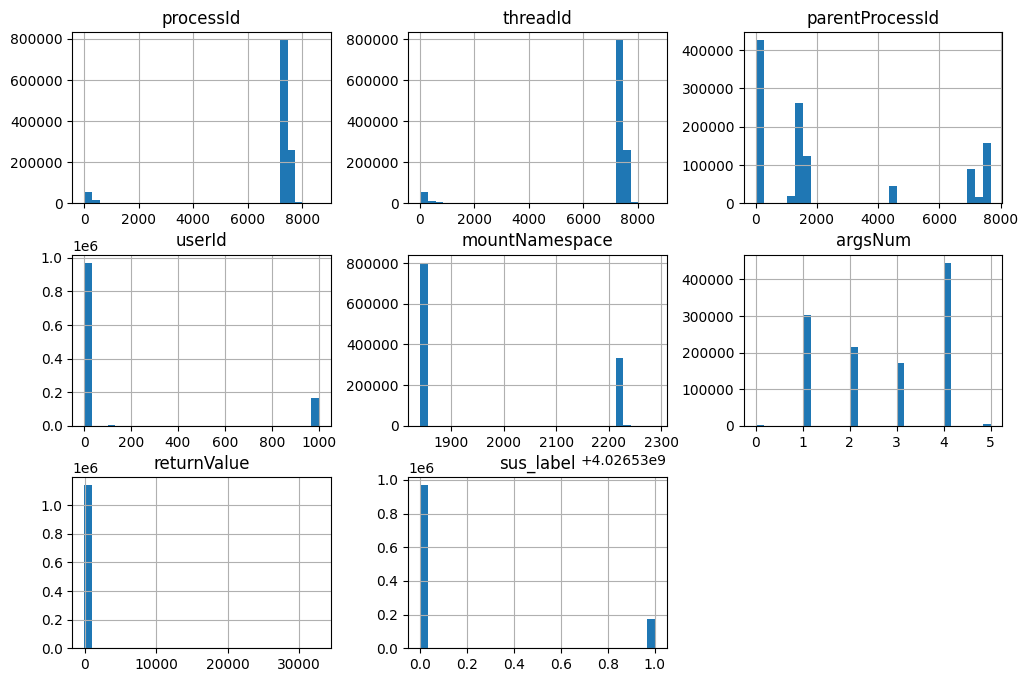

In [42]:
df.hist(bins=30, figsize=(12,8))

In [43]:
for col in df.columns:
  display(df[col].value_counts().sort_index(ascending=False)) # + no outliers

,count
processId,
8619,5
8289,88
8122,5
8121,5
8120,419
...,...
80,9
8,9
7,8


,count
threadId,
8619,5
8289,88
8122,5
8121,5
8120,419
...,...
80,9
8,9
7,8


,count
parentProcessId,
7672,22
7670,22
7667,22
7665,22
7662,22
...,...
188,59649
187,261959
2,1186


,count
userId,
1001,160987
1000,2037
109,1521
103,150
102,1394
101,3738
100,1224
0,970027


,count
mountNamespace,
4026532288,1183
4026532232,3738
4026532231,1224
4026532229,1394
4026532217,332402
4026531840,801137


,count
argsNum,
5,4013
4,445325
3,170531
2,216187
1,303123
0,1899


,count
returnValue,
32768,4
10592,4
8289,1
7912,8
7850,1
...,...
-20,100
-22,54
-111,789


,count
sus_label,
1,173514
0,967564


### Imbalanced Class :

In [44]:
df["sus_label"].value_counts(normalize=True) # i'll keep as it is for now, i'll try to fix later and see its effect on the accuracy

,proportion
sus_label,
0,0.847939
1,0.152061


# Scaling :

In [45]:
X_train, y_train = train_df.drop("sus_label", axis=1).values, train_df["sus_label"].values
X_test, y_test = test_df.drop("sus_label", axis=1).values, test_df["sus_label"].values
X_val, y_val = val_df.drop("sus_label", axis=1).values, val_df["sus_label"].values

In [46]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
X_val = sc.transform(X_val)

In [47]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_val = X_val.astype('float32')

y_train = y_train.astype('float32')
y_test = y_test.astype('float32')
y_val = y_val.astype('float32')

y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)

In [48]:
print(X_train.dtype, X_test.dtype, X_val.dtype)
print(y_train.shape, y_test.shape, y_val.shape)

float32 float32 float32
(763144, 1) (188967, 1) (188967, 1)


In [49]:
y_train.dtype

dtype('float32')

# ANN training :

In [62]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchmetrics.classification import BinaryAccuracy, BinaryConfusionMatrix, BinaryRecall, BinaryPrecision

### tensor datasets :

In [63]:
train_data = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
test_data = TensorDataset(torch.tensor(X_test), torch.tensor(y_test))
val_data = TensorDataset(torch.tensor(X_val), torch.tensor(y_val))

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=True)

### model & criterion & optimizer :

In [64]:
model = nn.Sequential(
  nn.Linear(7, 4),
  nn.ReLU(),
  
  nn.Linear(4, 1),
  nn.Sigmoid()
)

criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

### training loop :

In [ ]:
num_epochs = 10

train_loss_list = []
val_loss_list = []

for epoch in range(num_epochs):

	# training :
	model.train()
	train_loss = 0.0

	for X_batch, y_batch in train_loader:
		optimizer.zero_grad()

		logits = model(X_batch)
		loss = criterion(logits, y_batch)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss = train_loss / len(train_loader)
	train_loss_list.append(train_loss)

  # validation :
	model.eval()
	val_loss = 0.0

	with torch.no_grad():
		for X_batch, y_batch in val_loader:

			logits = model(X_batch)
			loss = criterion(logits, y_batch)
			val_loss += loss.item()

	val_loss = val_loss / len(val_loader)
	val_loss_list.append(val_loss)

	print(f"epoch : {epoch} train_loss : {train_loss:.6f} val_loss = {val_loss:.6f}")

epoch : 0 train_loss : 0.005597 val_loss = 0.000561
epoch : 1 train_loss : 0.002389 val_loss = 0.000554
epoch : 2 train_loss : 0.002261 val_loss = 0.000560
epoch : 3 train_loss : 0.002216 val_loss = 0.000555
epoch : 4 train_loss : 0.002185 val_loss = 0.000544
epoch : 5 train_loss : 0.002159 val_loss = 0.000543
epoch : 6 train_loss : 0.002144 val_loss = 0.000539
epoch : 7 train_loss : 0.002133 val_loss = 0.000534
epoch : 8 train_loss : 0.002119 val_loss = 0.000539
epoch : 9 train_loss : 0.002110 val_loss = 0.000534
epoch : 10 train_loss : 0.002097 val_loss = 0.000533
epoch : 11 train_loss : 0.002096 val_loss = 0.000530
epoch : 12 train_loss : 0.002080 val_loss = 0.000538
epoch : 13 train_loss : 0.002070 val_loss = 0.000528
epoch : 14 train_loss : 0.002040 val_loss = 0.000531
epoch : 15 train_loss : 0.002050 val_loss = 0.000529
epoch : 16 train_loss : 0.002026 val_loss = 0.000523
epoch : 17 train_loss : 0.002011 val_loss = 0.000534
epoch : 18 train_loss : 0.002018 val_loss = 0.000534
epo

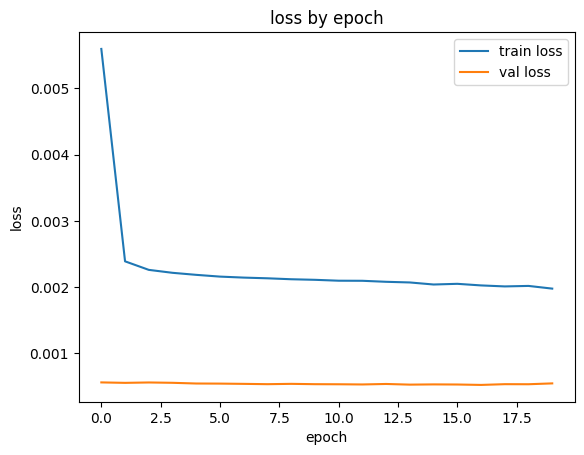

In [56]:
plt.plot(range(num_epochs), train_loss_list, label="train loss")
plt.plot(range(num_epochs), val_loss_list, label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("loss by epoch")
plt.legend()

### testing :

In [ ]:
accuracy = BinaryAccuracy()
recall = BinaryRecall()
precision = BinaryPrecision()
cm = BinaryConfusionMatrix()

model.eval()
with torch.no_grad():
		for X_batch, y_batch in test_loader:
				logits = model(X_batch)

				accuracy.update(logits, y_batch)
				recall.update(logits, y_batch)
				precision.update(logits, y_batch)
				cm.update(logits, y_batch)

print(f"accuracy : {accuracy.compute().item():.6f}")
print(f"recall : {recall.compute().item():.6f}")	
print(f"precision : {precision.compute().item():.6f}")
print(f"confusion matrix : \n{cm.compute().numpy()}")

accuracy : 0.932909
recall : 0.940056
precision : 0.985328
confusion matrix : 
[[ 15108   2400]
 [ 10278 161181]]
